# Unsupervised AD with isolation forest
## Synthetic machine data example

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler

from google.colab import files

# Load data




In [ ]:
import pandas as pd
option=2
if option==1:
  # easy
  url = "https://drive.google.com/uc?export=download&id=1-6nz0ldZcD6zflGE2QnExvfoMYaioOH4"
elif option==2:
  # hard
  url = "https://drive.google.com/uc?export=download&id=1lo7kzz6nGQYiM18dnN5dodgMUDmjym_g"


# Load the CSV into a DataFrame directly from the URL
df = pd.read_csv(url)

# Display the first few rows to confirm
df.head()

,temperature,vibrations,state,label
0,65.908897,5.092387,2.0,0.0
1,36.991467,10.778417,1.0,0.0
2,33.815246,6.019315,1.0,0.0
3,41.070469,6.131392,1.0,0.0
4,70.379023,2.322838,2.0,0.0


# Single state data
**Text fett markieren**

In [ ]:
which_state = 1
mask = (df['state']==which_state) | (df['state']==-1)
df_1state = df[mask].copy()


## Random shuffling of the rows of the dataframe

In [ ]:
# Shuffle the rows of the DataFrame
df_1state = df_1state.sample(frac=1, random_state=42).reset_index(drop=True)


Text(0, 0.5, 'Vibrations')

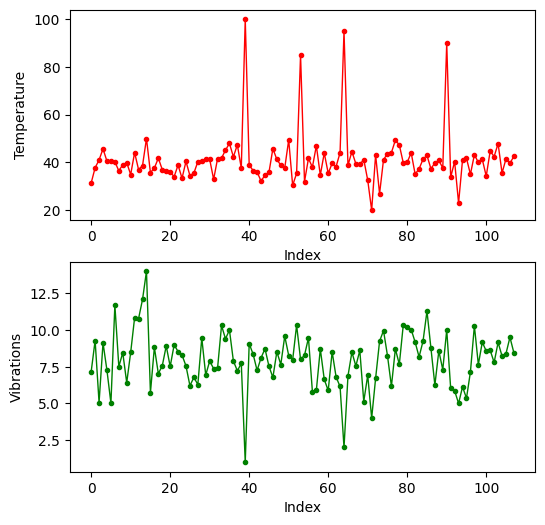

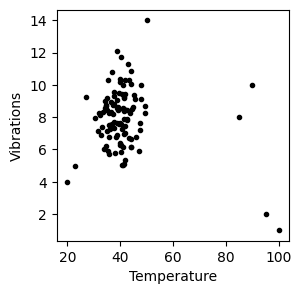

In [ ]:
# serial plots
fig, axes = plt.subplots(2, 1, figsize=(6, 6))

axes[0].set_xlabel("Index")
axes[0].set_ylabel("Temperature")
axes[0].plot(df_1state['temperature'],'o-r',ms=3,lw=1)

axes[1].set_xlabel("Index")
axes[1].set_ylabel("Vibrations")
axes[1].plot(df_1state['vibrations'],'o-g',ms=3,lw=1)

# scatter plot
plt.figure(figsize=(3,3))
plt.plot(df_1state['temperature'],df_1state['vibrations'],'ok',ms=3)
plt.xlabel('Temperature')
plt.ylabel('Vibrations')

## Extract only the variables from the dataframe

In [ ]:
data = df_1state[['temperature','vibrations']].copy().values

## Fit and predict with iForest

In [ ]:
# Step 2: Apply Robust Scaling (using median and IQR)
scaler = RobustScaler()
data_scaled = scaler.fit_transform(data)

# Step 3: Apply Isolation Forest
isolation_forest = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)
outliers = isolation_forest.fit_predict(data_scaled)

# Step 4: Convert the output: 1 = normal, -1 = anomaly
outliers = np.where(outliers == 1, 0, 1)  # Convert to 0 for normal and 1 for anomaly

## Plot iForest predictions

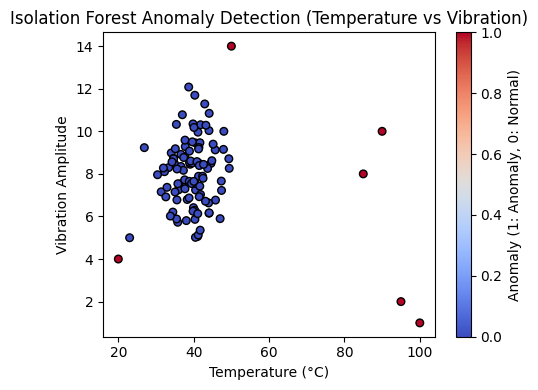

In [ ]:
# Step 5: Visualize the results
plt.figure(figsize=(5, 4))

# Scatter plot, color by anomaly detection results
plt.scatter(data[:, 0], data[:, 1], c=outliers, cmap='coolwarm', edgecolor='k', s=30)
plt.title("Isolation Forest Anomaly Detection (Temperature vs Vibration)")
plt.xlabel("Temperature (°C)")
plt.ylabel("Vibration Amplitude")
plt.colorbar(label='Anomaly (1: Anomaly, 0: Normal)')

plt.tight_layout()
plt.show()

## Plot iForest anomaly scores

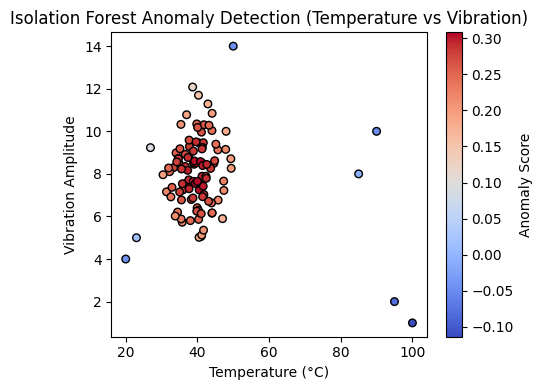

In [ ]:
# Step 4: Get anomaly scores (lower scores indicate more anomalous points)
if_scores = isolation_forest.decision_function(data_scaled)

# Step 5: Visualize the results using anomaly scores as the color of the points
plt.figure(figsize=(5, 4))

# Scatter plot, color by anomaly score (more negative means more anomalous)
scatter = plt.scatter(
    data[:, 0], data[:, 1],
    c=if_scores, cmap='coolwarm', edgecolor='k', s=30
)
plt.title("Isolation Forest Anomaly Detection (Temperature vs Vibration)")
plt.xlabel("Temperature (°C)")
plt.ylabel("Vibration Amplitude")

# Add colorbar to represent anomaly scores
plt.colorbar(scatter, label='Anomaly Score')

plt.tight_layout()
plt.show()

## Detection threshold

In [ ]:

# calculate  statistics of the score over samples
score_mean =  np.mean(if_scores)
score_std = np.std(if_scores)

# define threshold for detection
score_threshold = score_mean - 3*score_std

# count how many anomalies are detected
np.sum(if_scores < score_threshold)

np.int64(5)

Text(0.5, 0, 'anomaly score')

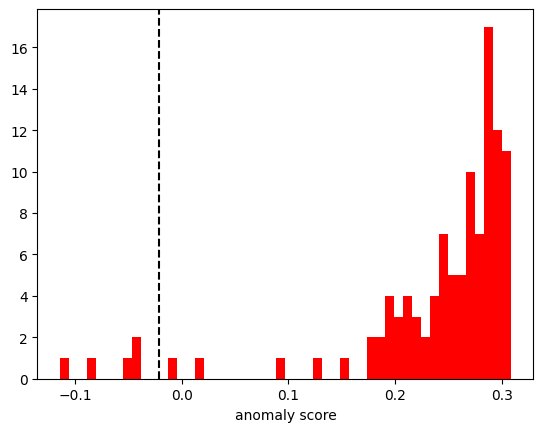

In [ ]:
plt.figure()
plt.hist(if_scores,50,color = 'r')
plt.axvline(x=score_threshold, color='k', linestyle='--')
plt.xlabel('anomaly score')

## Detection threshold: robust

In [ ]:
# calculate  statistics of the score over samples
score_median =  np.median(if_scores)
score_iqr = np.quantile(if_scores,0.75)-np.quantile(if_scores,0.25)

# define threshold for detection
score_threshold = score_median - 3*score_iqr

# count how many anomalies are detected
np.sum(if_scores < score_threshold)

np.int64(7)

## Plot robust threshold

Text(0.5, 0, 'anomaly score')

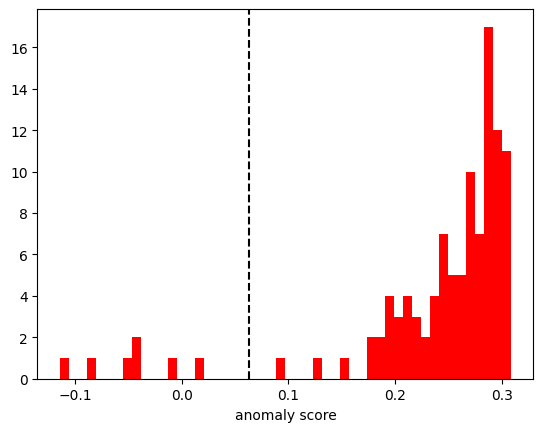

In [ ]:
plt.figure()
plt.hist(if_scores,50,color = 'r')
plt.axvline(x=score_threshold, color='k', linestyle='--')
plt.xlabel('anomaly score')

# Two state data


## Random shuffling of the rows of the dataframe

In [ ]:
# Shuffle the rows of the DataFrame
df = df.sample(frac=1, random_state=42).reset_index(drop=True)


## Visualize the data

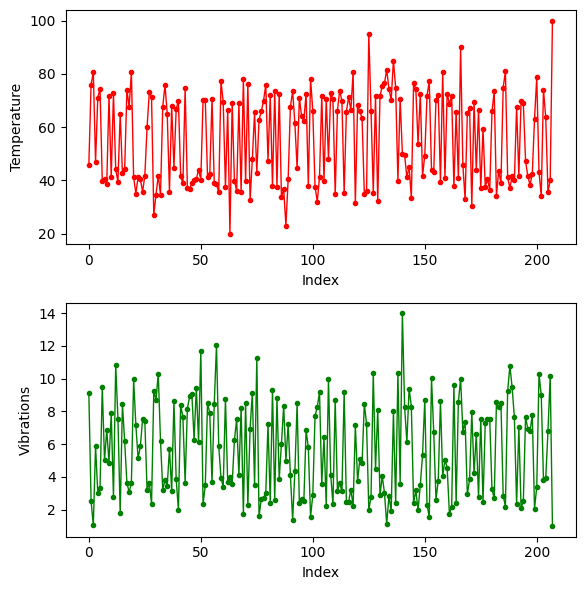

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

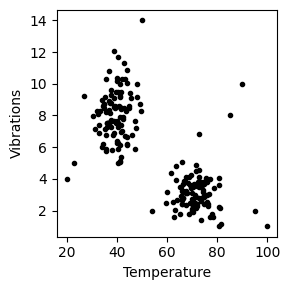

In [ ]:
# serial plots
fig, axes = plt.subplots(2, 1, figsize=(6, 6))

axes[0].set_xlabel("Index")
axes[0].set_ylabel("Temperature")
axes[0].plot(df['temperature'],'o-r',ms=3,lw=1)

axes[1].set_xlabel("Index")
axes[1].set_ylabel("Vibrations")
axes[1].plot(df['vibrations'],'o-g',ms=3,lw=1)
plt.tight_layout()

plt.savefig('TempVibTimeseries.pdf')  # Save the figure
plt.show()

# Download the figure
#files.download('TempVibTimeseries.pdf')

# scatter plot
plt.figure(figsize=(3,3))
plt.plot(df['temperature'],df['vibrations'],'ok',ms=3)
plt.xlabel('Temperature')
plt.ylabel('Vibrations')
plt.tight_layout()
plt.savefig('TempVibScatter.pdf')  # Save the figure
plt.show()

# Download the figure
#files.download('TempVibScatter.pdf')

## Extract only the variables from the dataframe

In [ ]:
data = df[['temperature','vibrations']].copy().values

## Fit and predict with iForest

In [ ]:
# Step 2: Apply Robust Scaling (using median and IQR)
scaler = RobustScaler()
data_scaled = scaler.fit_transform(data)

# Step 3: Apply Isolation Forest
isolation_forest = IsolationForest(n_estimators=100, contamination=0.05, random_state=42)
outliers = isolation_forest.fit_predict(data_scaled)

# Step 4: Convert the output: 1 = normal, -1 = anomaly
outliers = np.where(outliers == 1, 0, 1)  # Convert to 0 for normal and 1 for anomaly

## Plot iForest predictions

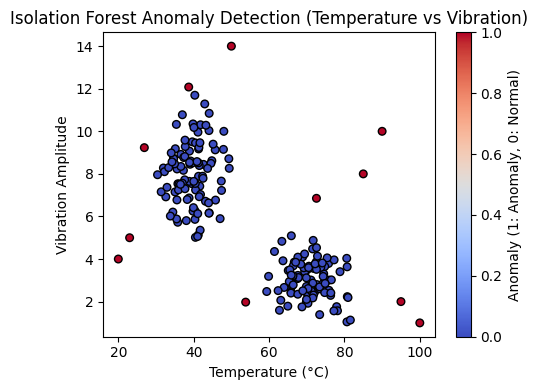

In [ ]:
# Step 5: Visualize the results
plt.figure(figsize=(5, 4))

# Scatter plot, color by anomaly detection results
plt.scatter(data[:, 0], data[:, 1], c=outliers, cmap='coolwarm', edgecolor='k', s=30)
plt.title("Isolation Forest Anomaly Detection (Temperature vs Vibration)")
plt.xlabel("Temperature (°C)")
plt.ylabel("Vibration Amplitude")
plt.colorbar(label='Anomaly (1: Anomaly, 0: Normal)')

plt.tight_layout()
plt.show()

## Plot iForest anomaly scores

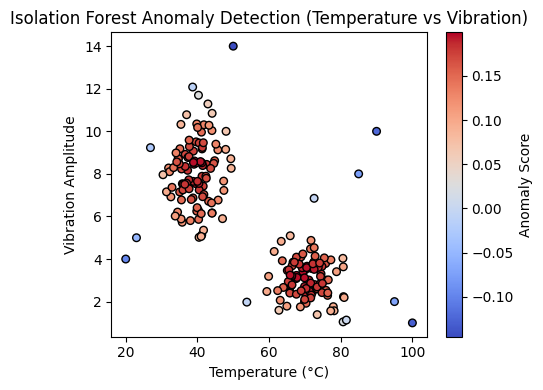

In [ ]:
# Step 4: Get anomaly scores (lower scores indicate more anomalous points)
if_scores = isolation_forest.decision_function(data_scaled)

# Step 5: Visualize the results using anomaly scores as the color of the points
plt.figure(figsize=(5, 4))

# Scatter plot, color by anomaly score (more negative means more anomalous)
scatter = plt.scatter(
    data[:, 0], data[:, 1],
    c=if_scores, cmap='coolwarm', edgecolor='k', s=30
)
plt.title("Isolation Forest Anomaly Detection (Temperature vs Vibration)")
plt.xlabel("Temperature (°C)")
plt.ylabel("Vibration Amplitude")

# Add colorbar to represent anomaly scores
plt.colorbar(scatter, label='Anomaly Score')

plt.tight_layout()
plt.show()

## Detection threshold

In [ ]:

# calculate robust statistics of the score over samples
score_mean =  np.mean(if_scores)
score_std = np.std(if_scores)

# define threshold for detection
score_threshold = score_mean - 3*score_std

# count how many anomalies are detected
np.sum(if_scores < score_threshold)

np.int64(6)

Text(0.5, 0, 'anomaly score')

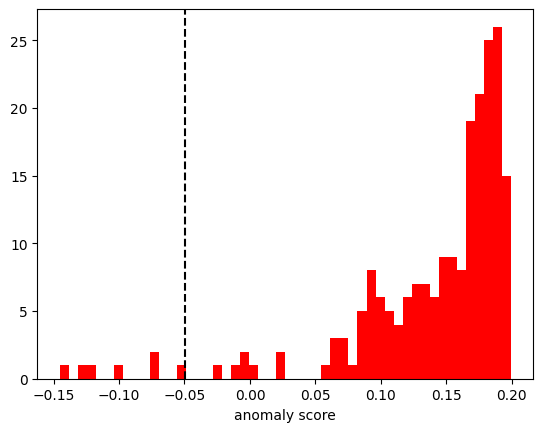

In [ ]:
plt.figure()
plt.hist(if_scores,50,color = 'r')
plt.axvline(x=score_threshold, color='k', linestyle='--')
plt.xlabel('anomaly score')

## Detection threshold: robust

In [ ]:
# calculate  statistics of the score over samples
score_median =  np.median(if_scores)
score_iqr = np.quantile(if_scores,0.75)-np.quantile(if_scores,0.25)

# define threshold for detection
score_threshold = score_median - 3*score_iqr

# count how many anomalies are detected
np.sum(if_scores < score_threshold)

np.int64(7)

## Plot robust threshold

Text(0.5, 0, 'anomaly score')

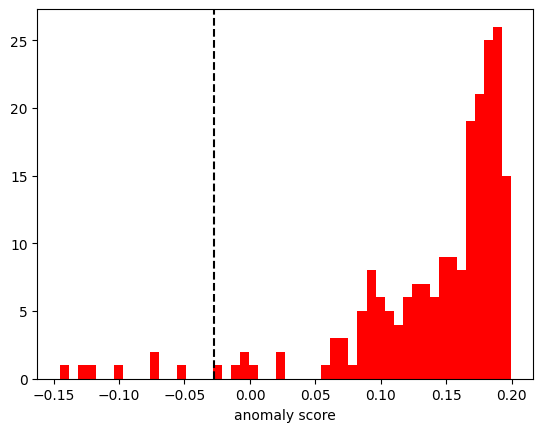

In [ ]:
plt.figure()
plt.hist(if_scores,50,color = 'r')
plt.axvline(x=score_threshold, color='k', linestyle='--')
plt.xlabel('anomaly score')

# Evaluation

In [ ]:
anomaly_scores = -if_scores # standard: anomalies have a higher score
true_labels = df['label']

## Confusion matrix

In [ ]:
# select a decision threshold and use it to predict
threshold = -score_threshold
predicted_labels = (anomaly_scores >= threshold).astype(int)
# True Positives, False Positives, False Negatives
tp = ((predicted_labels == 1) & (true_labels == 1)).sum()
tn = ((predicted_labels == 0) & (true_labels == 0)).sum()
fp = ((predicted_labels == 1) & (true_labels == 0)).sum()
fn = ((predicted_labels == 0) & (true_labels == 1)).sum()

print(tp,tn,fp,fn)

7 200 0 1


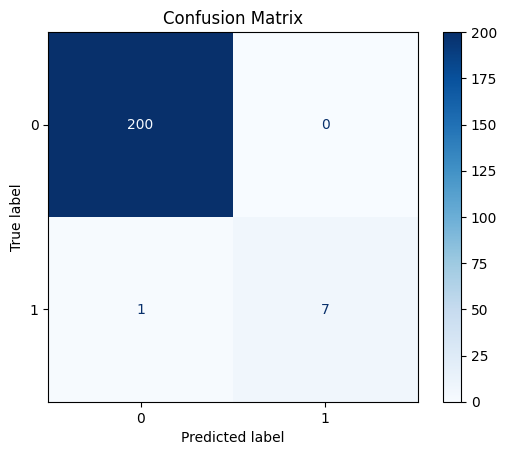

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(true_labels, predicted_labels)
# Plot the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()

## Precision-recall curve

In [ ]:
def calculate_precision_recall_from_scratch(anomaly_scores, true_labels, threshold_array):
    """
    Calculate precision and recall for a given set of thresholds from scratch.

    Parameters:
    - anomaly_scores: Array-like, the anomaly scores output by the isolation forest.
                      Higher scores indicate a higher likelihood of being an anomaly.
    - true_labels: Array-like, ground truth labels (0 for normal, 1 for anomalies).
    - threshold_array: List or array of thresholds to evaluate.

    Returns:
    - precision: List of precision values for each threshold.
    - recall: List of recall values for each threshold.
    """
    precision = []
    recall = []

    for threshold in threshold_array:
        # Classify points as anomalies (1) or normal (0) based on the threshold
        predicted_labels = (anomaly_scores >= threshold).astype(int)

        # True Positives, False Positives, False Negatives
        tp = ((predicted_labels == 1) & (true_labels == 1)).sum()
        fp = ((predicted_labels == 1) & (true_labels == 0)).sum()
        fn = ((predicted_labels == 0) & (true_labels == 1)).sum()

        # Precision and Recall calculations
        prec = tp / (tp + fp) if (tp + fp) > 0 else 0
        rec = tp / (tp + fn) if (tp + fn) > 0 else 0

        precision.append(prec)
        recall.append(rec)

    return precision, recall



### Define a set of thresholds

In [ ]:
threshold_arr = np.arange(np.min(anomaly_scores),np.max(anomaly_scores),0.01)
threshold_arr

array([-0.19926416, -0.18926416, -0.17926416, -0.16926416, -0.15926416,
       -0.14926416, -0.13926416, -0.12926416, -0.11926416, -0.10926416,
       -0.09926416, -0.08926416, -0.07926416, -0.06926416, -0.05926416,
       -0.04926416, -0.03926416, -0.02926416, -0.01926416, -0.00926416,
        0.00073584,  0.01073584,  0.02073584,  0.03073584,  0.04073584,
        0.05073584,  0.06073584,  0.07073584,  0.08073584,  0.09073584,
        0.10073584,  0.11073584,  0.12073584,  0.13073584,  0.14073584])

### calculate precision and recall using own function

In [ ]:
precision, recall = calculate_precision_recall_from_scratch(anomaly_scores, true_labels, threshold_arr)

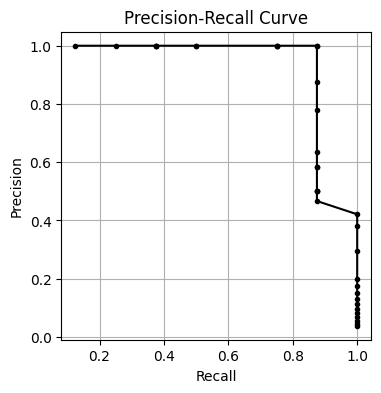

In [ ]:
plt.figure(figsize=(4, 4))
plt.plot(recall,precision,'ko-',ms=3)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.grid()
plt.show()

### calculate precision and recall using sklearn function

In [ ]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

def calculate_pr_curve(anomaly_scores, true_labels, plot=True):
    """
    Calculate and optionally plot the Precision-Recall (PR) curve.

    Parameters:
    - anomaly_scores: Array-like, the anomaly scores output by the isolation forest.
                      Higher scores should correspond to higher likelihood of being an anomaly.
    - true_labels: Array-like, ground truth labels (0 for normal, 1 for anomalies).
    - plot: Boolean, whether to plot the PR curve (default is True).

    Returns:
    - precision: Array of precision values.
    - recall: Array of recall values.
    - thresholds: Array of thresholds used to compute precision and recall.
    """
    # Calculate Precision-Recall curve
    precision, recall, thresholds = precision_recall_curve(true_labels, anomaly_scores)

    if plot:
        # Plot the PR curve
        plt.figure(figsize=(4, 4))
        plt.plot(recall, precision, marker='.', label='PR Curve')
        plt.xlabel('Recall')
        plt.ylabel('Precision')
        plt.title('Precision-Recall Curve')
        plt.legend()
        plt.grid()
        plt.show()

    return precision, recall, thresholds


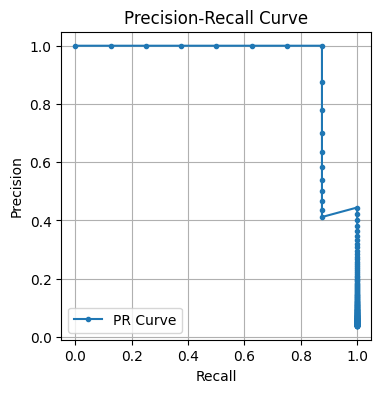

In [ ]:
prec, rec, thresholds = calculate_pr_curve(anomaly_scores,df['label'])